# Etapa 5 — análise quantitativa

Notebook reprodutível para as perguntas QP1–QP3 do pitch, seguindo as definições operacionais em `definicoes.md` e as ressalvas de `analise.md`. A coorte é de contas criadas em março de 2025; a permanência é uma edição visível entre os dias 31 e 90 após a criação.

**Limites importantes:** o estudo é observacional; não demonstra causalidade. A codificação de `piloto_codificador_1.csv` foi feita em discussão coletiva e serve como consenso exploratório para os 30 casos do piloto, não como duas avaliações independentes. Portanto, não calculamos kappa. O restante da amostra não foi codificado e não é possível estimar resultados de boa-fé ou qualidade das explicações para toda a amostra.

In [2]:
from pathlib import Path
import sys

ROOT = Path.cwd()
if not (ROOT / "dados" / "base.csv").exists():
    ROOT = ROOT.parent
if not (ROOT / "dados" / "base.csv").exists():
    raise FileNotFoundError("Abra o notebook na raiz do repositório.")
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display
from scripts import gerar_graficos

## Reproduzir tabelas e figuras

A função principal lê os CSVs coletados e recria as tabelas de proporções, testes, modelos e os cinco gráficos em `graficos/`. Ela também gera `dados/etapa5_qp2.csv`, com autoria das reversões e presença de sumário.

In [3]:
gerar_graficos.main()

base = pd.read_csv(ROOT / "dados" / "base.csv")
reversoes = pd.read_csv(ROOT / "dados" / "reversoes.csv")
resumo = pd.read_csv(ROOT / "dados" / "resultados_quantitativos.csv")
testes = pd.read_csv(ROOT / "dados" / "testes_associacao.csv")
modelos = pd.read_csv(ROOT / "dados" / "modelos_logisticos.csv")
qp2 = pd.read_csv(ROOT / "dados" / "etapa5_qp2.csv")

assert len(base) == 2638
assert int(base["na_analise_permanencia"].sum()) == 2100
assert int((base["na_analise_permanencia"].eq(1) & base["comparavel"].eq(1)).sum()) == 2015
assert int(reversoes["situacao"].eq("revertida").sum()) == 886
print("Contagens esperadas verificadas.")

Análises concluídas.
  Resumo: dados/resultados_quantitativos.csv
  Testes: dados/testes_associacao.csv
  Modelos: dados/modelos_logisticos.csv
  QP2: dados/etapa5_qp2.csv
  Gráficos: graficos

Proporções de permanência:
analise                     grupo    n  eventos  proporcao  ic95_inferior  ic95_superior
    QP3     Permaneceu: Revertida  623       22   0.035313       0.023434       0.052887
    QP3 Permaneceu: Não revertida 1392      132   0.094828       0.080533       0.111353
    QP3 Permaneceu: Recebeu aviso  645       32   0.049612       0.035359       0.069198
    QP3     Permaneceu: Sem aviso 1455      136   0.093471       0.079566       0.109517

Testes de associação:
                              comparacao variavel_exposicao    n      chi2  graus_liberdade  p_valor  correcao_yates                                                                                  tabela_2x2
              H1: reversão x permanência          revertida 2015 20.761511                1 0.000005  

## QP1 — primeira experiência, reversão e recepção

Entre 2.516 primeiras edições comparáveis em toda a base, 886 (35,2%; IC95% 33,4–37,1%) foram revertidas em até 48 horas. Entre as 886 reversões, 697 (78,7%) ocorreram na primeira hora, 165 (18,6%) entre 1 e 24 horas e 24 (2,7%) entre 24 e 48 horas. A mediana até a reversão foi de 6,9 minutos.

Na primeira semana, entre 2.638 novatos, 1.666 (63,2%) não tiveram contato humano classificado, 954 (36,2%) receberam aviso (categoria que inclui bloqueio) e 18 (0,7%) receberam outra mensagem. A categoria foi atribuída por palavras-chave no sumário da edição da mensagem; não identifica um motivo específico nem garante uma advertência formal. Boas-vindas automáticas foram excluídas.

In [4]:
resumo.query("analise == 'QP1'").style.format({
    "proporcao": "{:.1%}", "ic95_inferior": "{:.1%}", "ic95_superior": "{:.1%}"
})

,analise,grupo,n,eventos,proporcao,ic95_inferior,ic95_superior
5,QP1,Primeira edição revertida (até 48 h),2516,886,35.2%,33.4%,37.1%
6,QP1,Revertidas em até 1 h,886,697,78.7%,75.8%,81.2%
7,QP1,Revertidas em >1 a 24 h,886,165,18.6%,16.2%,21.3%
8,QP1,Revertidas em >24 a 48 h,886,24,2.7%,1.8%,4.0%
9,QP1,Recepção na semana: nenhuma,2638,1666,63.2%,61.3%,65.0%
10,QP1,Recepção na semana: aviso,2638,954,36.2%,34.4%,38.0%
11,QP1,Recepção na semana: outra,2638,18,0.7%,0.4%,1.1%


## QP2 — autoria das reversões e limites da justificativa

Das 886 reversões, 505 (57,0%) foram atribuídas a humanos, 381 (43,0%) a ferramentas semiautomáticas e nenhuma a robôs. Há sumário em 882 registros (99,5%), mas sua presença **não** prova que a justificativa seja clara ou específica. A classificação qualitativa da explicação só pode ser feita lendo e codificando cada caso; os 30 casos do piloto não representam as 886 reversões.

In [5]:
qp2.style.format({
    "proporcao": "{:.1%}", "ic95_inferior": "{:.1%}", "ic95_superior": "{:.1%}"
})

,indicador,eventos,total_reversoes,proporcao,ic95_inferior,ic95_superior
0,Reversões feitas por humanos,505,886,57.0%,53.7%,60.2%
1,Reversões feitas por ferramenta semiautomática,381,886,43.0%,39.8%,46.3%
2,Reversões feitas por robôs,0,886,0.0%,0.0%,0.4%
3,Reversões com sumário registrado (não mede qualidade da explicação),882,886,99.5%,98.8%,99.8%
4,Reversões sem sumário registrado,4,886,0.5%,0.2%,1.2%


## QP3 — associação com permanência

Na análise elegível, permaneceram 22/623 (3,5%) entre os revertidos e 132/1.392 (9,5%) entre os não revertidos. A associação bruta foi χ²(1)=20,76, p<0,001. No modelo ajustado, OR=0,47 (IC95% 0,26–0,86; p=0,014).

Entre todos os elegíveis, permaneceram 32/645 (5,0%) dos que receberam aviso/bloqueio e 136/1.455 (9,3%) dos que não receberam; χ²(1)=11,09, p<0,001. No modelo global ajustado, OR=0,45 (IC95% 0,30–0,67; p<0,001). Porém, dentro do estrato revertido, a associação com aviso não foi detectável: χ²(1)=0,21, p=0,646; OR ajustado=1,12 (IC95% 0,31–3,98; p=0,864). O intervalo é amplo e há poucos eventos nesse grupo.

Não foi executada a análise de permanência restrita a novatos codificados como `boa_fe`: só os 30 casos do piloto têm codificação consensual. Essa subamostra exploratória não deve ser apresentada como estimativa para a população nem substitui a codificação da amostra completa.

In [6]:
display(resumo.query("analise == 'QP3'").style.format({
    "proporcao": "{:.1%}", "ic95_inferior": "{:.1%}", "ic95_superior": "{:.1%}"
}))
display(testes)
modelos.query("variavel in ['revertida', 'recebeu_aviso']")

,analise,grupo,n,eventos,proporcao,ic95_inferior,ic95_superior
15,QP3,Permaneceu: Revertida,623,22,3.5%,2.3%,5.3%
16,QP3,Permaneceu: Não revertida,1392,132,9.5%,8.1%,11.1%
17,QP3,Permaneceu: Recebeu aviso,645,32,5.0%,3.5%,6.9%
18,QP3,Permaneceu: Sem aviso,1455,136,9.3%,8.0%,11.0%


,comparacao,variavel_exposicao,n,chi2,graus_liberdade,p_valor,correcao_yates,tabela_2x2
0,H1: reversão x permanência,revertida,2015,20.761511,1,0.000005,True,"exposto: não permaneceu=601, permaneceu=22; re..."
1,H2: aviso x permanência,recebeu_aviso,2100,11.091378,1,0.000867,True,"exposto: não permaneceu=613, permaneceu=32; re..."
2,H2: aviso x permanência entre revertidos,recebeu_aviso,623,0.211573,1,0.645537,True,"exposto: não permaneceu=481, permaneceu=19; re..."


,modelo,variavel,n,odds_ratio,ic95_inferior,ic95_superior,p_valor,formula
4,H1 - comparáveis,revertida,2015,0.468585,0.255419,0.859655,0.014349,permaneceu ~ revertida + recebeu_aviso + log_e...
5,H1 - comparáveis,recebeu_aviso,2015,0.749300,0.430387,1.304526,0.307616,permaneceu ~ revertida + recebeu_aviso + log_e...
11,H2 - elegíveis,recebeu_aviso,2100,0.447534,0.297382,0.673500,0.000116,permaneceu ~ recebeu_aviso + log_edicoes_24h +...
18,H2 - revertidos,recebeu_aviso,623,1.117321,0.313987,3.975982,0.863994,permaneceu ~ recebeu_aviso + log_edicoes_24h +...


## Figuras para apresentação

O passo a passo recomenda dois ou três gráficos para o artigo. Para os slides, priorize reversão, recepção e permanência; os gráficos de tempo e autoria podem entrar como apoio para responder QP1 e QP2.

reversoes_primeira_edicao.png


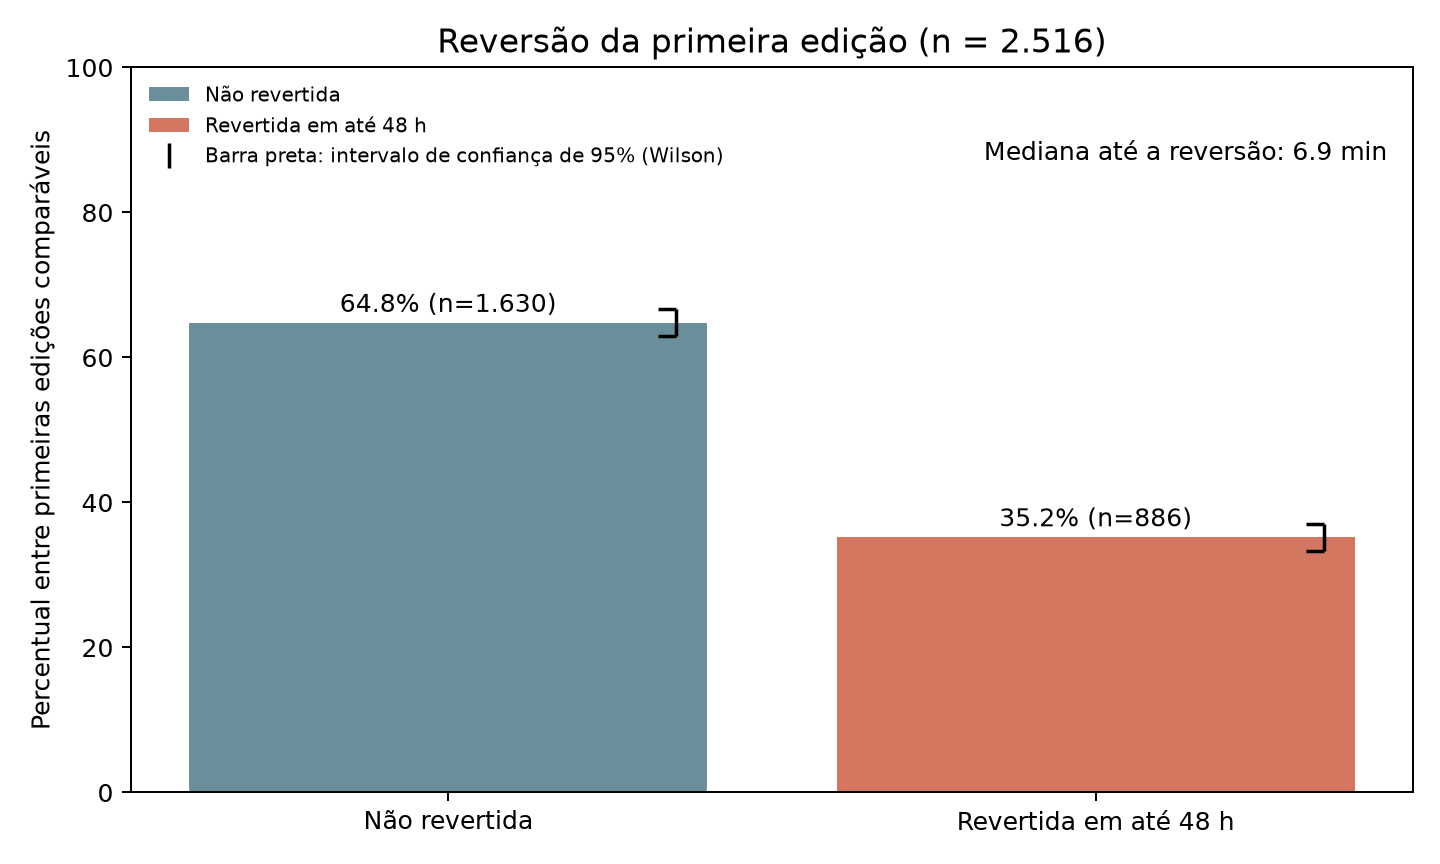

recepcao_primeira_semana.png


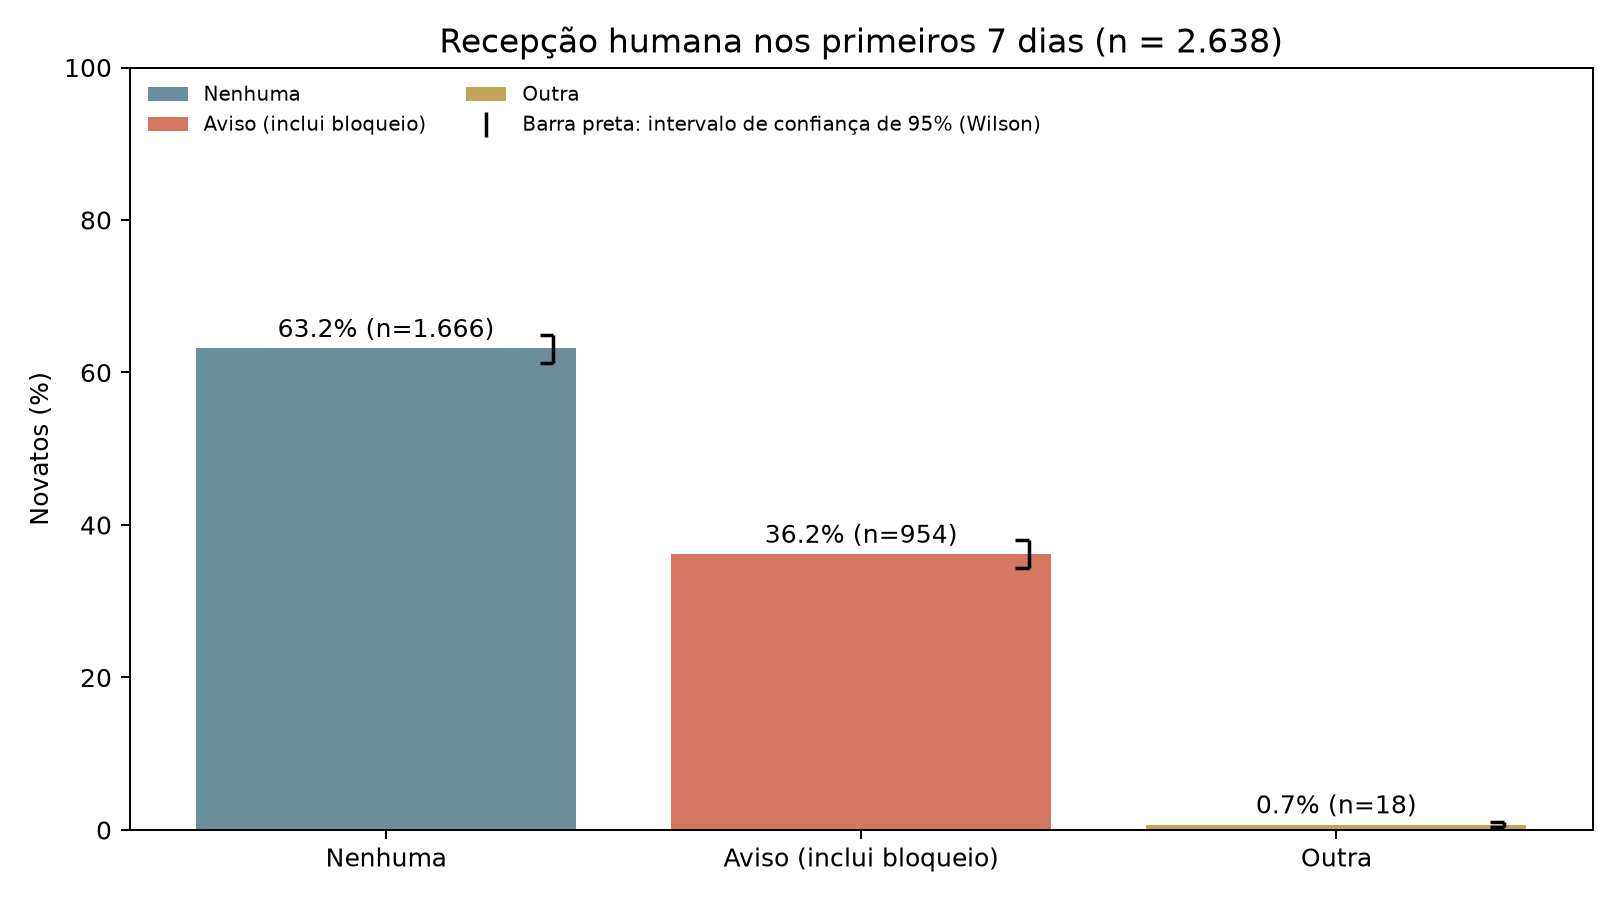

permanencia_por_recepcao.png


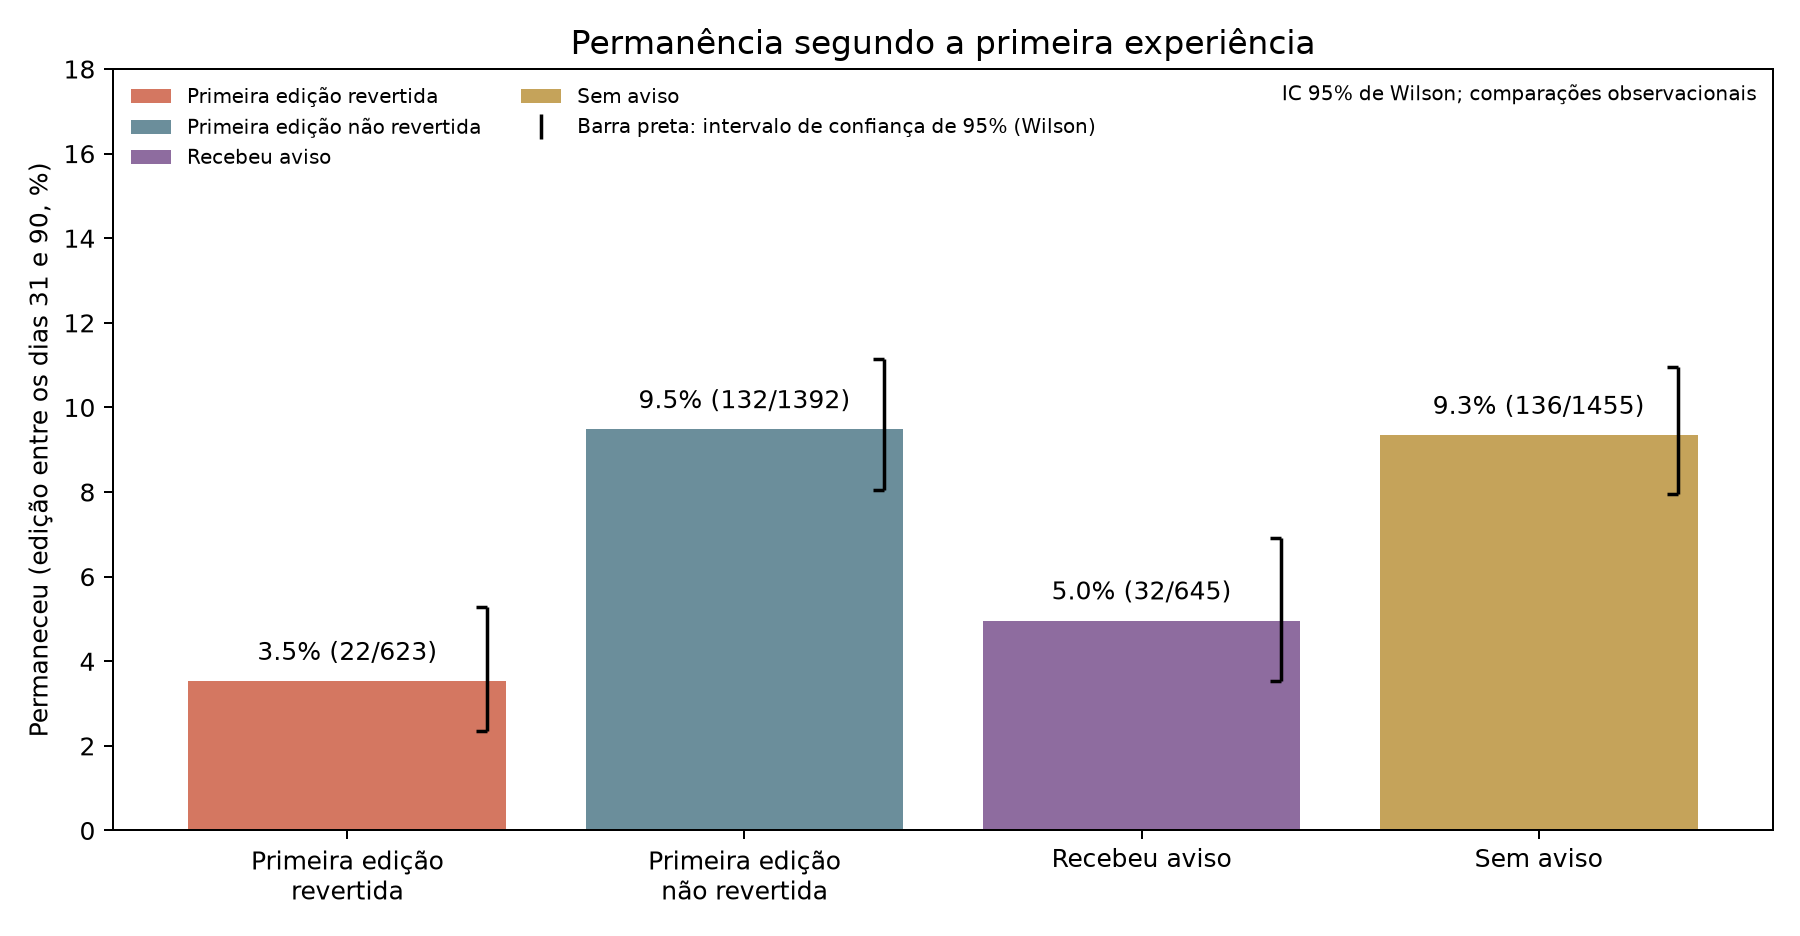

tempo_ate_reversao.png


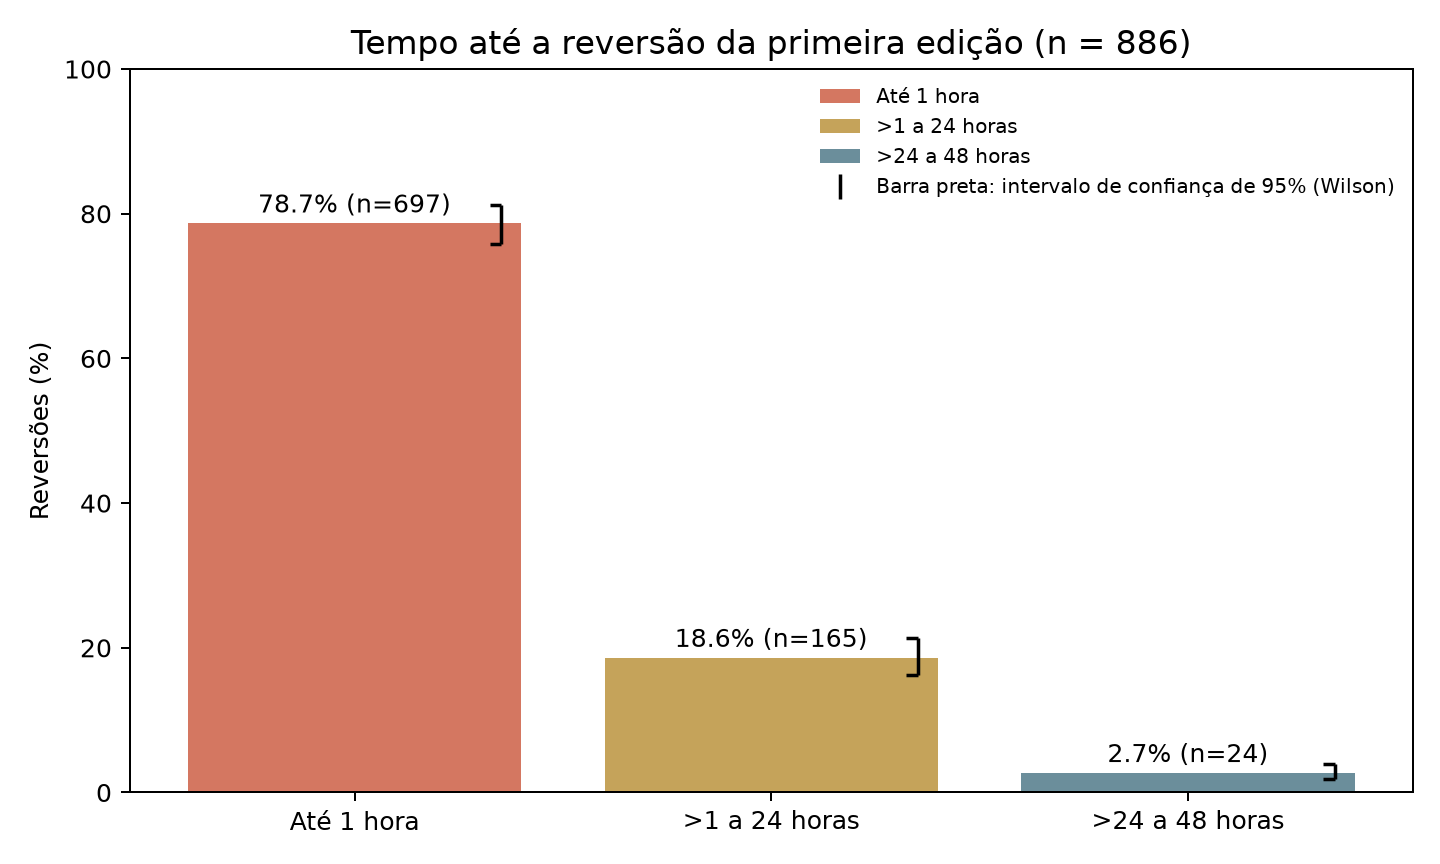

tipo_revertor_primeira_edicao.png


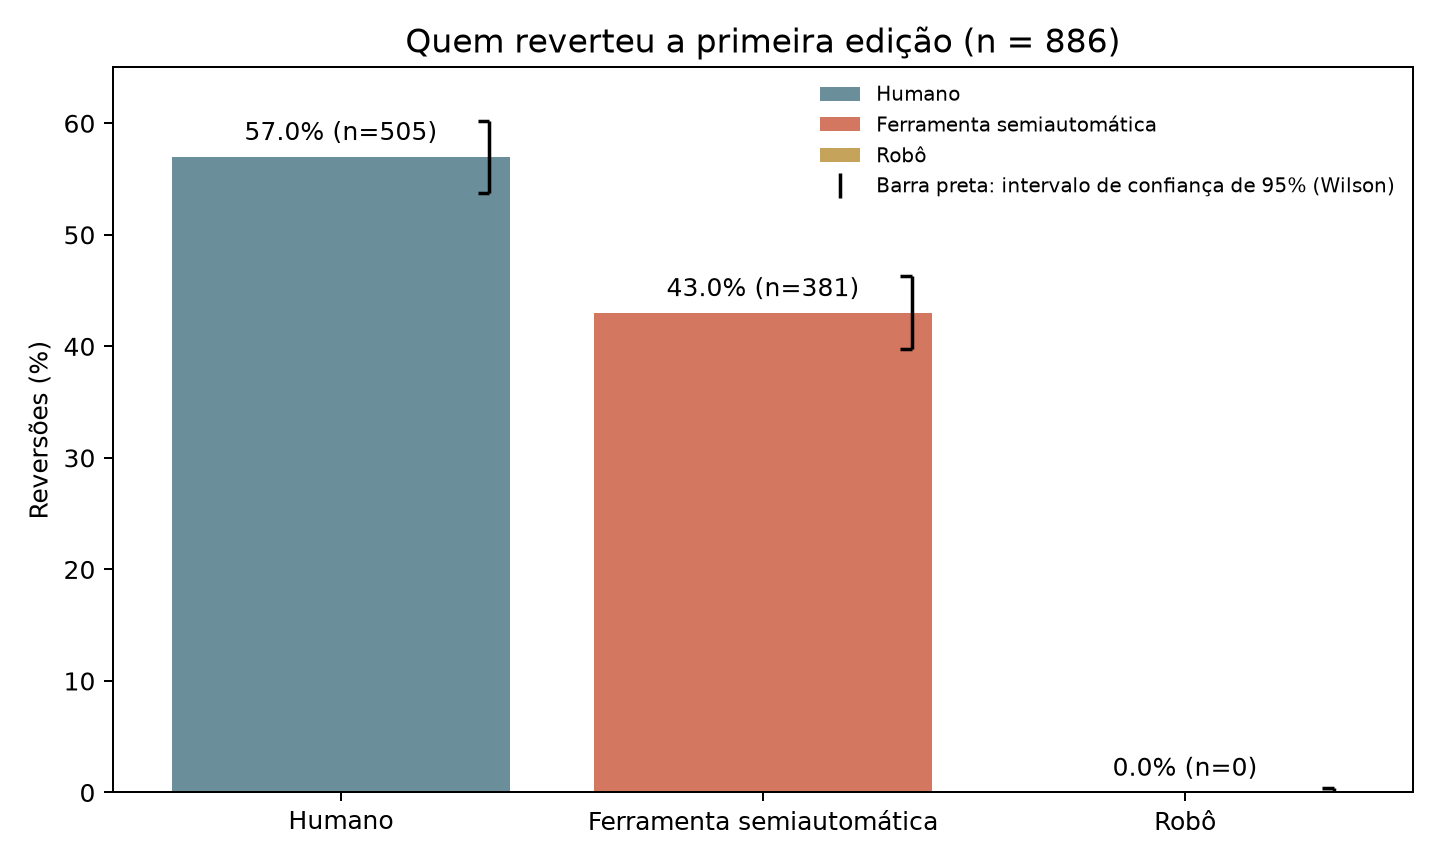

In [9]:
for nome in [
    "reversoes_primeira_edicao.png",
    "recepcao_primeira_semana.png",
    "permanencia_por_recepcao.png",
    "tempo_ate_reversao.png",
    "tipo_revertor_primeira_edicao.png",
]:
    print(nome)
    display(Image(filename=str(ROOT / "graficos" / nome)))

## Piloto de codificação consensual

O arquivo `dados/piloto_codificador_1.csv` contém 30 casos discutidos pelo grupo. As contagens abaixo descrevem somente esse piloto (boa-fé: 16 `boa_fe`, 9 `indeterminada`, 5 `ma_fe`; explicação: 7 específica, 9 genérica, 2 incerta, 12 não aplicável; tom: 2 acolhedor-construtivo, 6 neutro-informativo, 6 misto/incerto, 16 sem mensagem). Como houve discussão conjunta, não são avaliações independentes; não calcular kappa. Não generalizar essas proporções à amostra ou à coorte.

In [8]:
piloto = pd.read_csv(ROOT / "dados" / "piloto_codificador_1.csv", keep_default_na=False)
assert len(piloto) == 30
for coluna in ["boa_fe", "explicacao_reversao", "tom_mensagem"]:
    display(piloto[coluna].value_counts().rename_axis("categoria").to_frame("n"))

,n
categoria,
boa_fe,16
indeterminada,9
ma_fe,5


,n
categoria,
nao_aplicavel,12
generica,9
especifica,7
incerta,2


,n
categoria,
sem_mensagem,16
neutro_informativo,6
misto_ou_incerto,6
acolhedor_construtivo,2


## Comparação com Halfaker et al. (2013)

Halfaker et al. relacionam mecanismos mais restritivos de controle de qualidade à queda da retenção de novatos na Wikipédia em inglês. A comparação aqui é conceitual: idioma, período, definição de primeira experiência, janela de permanência e critérios de inclusão diferem. Não comparar diretamente percentuais como se medissem a mesma população ou evento. Referência: Halfaker, A. et al. (2013), *The Rise and Decline of an Open Collaboration System*, American Behavioral Scientist, 57(5), 664–688. [DOI: 10.1177/0002764212469365](https://doi.org/10.1177/0002764212469365).